# Imports and setup

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

from demand.config import PROCESSED, HORIZON

sns.set_theme(style="whitegrid")

# Load and split data

In [42]:
df = pd.read_parquet(PROCESSED / "subset.parquet")
cutoff = df.date.max() - pd.Timedelta(days=HORIZON)
eda = df[df.date <= cutoff].copy()
print("EDA period:", eda.date.min().date(), "->", eda.date.max().date())

EDA period: 2015-08-16 -> 2017-07-18


# Read data

In [43]:
print("================ Shape ================")
print(eda.shape)

print("================ Info ================")
print(eda.info())

print("================ Describe ================")
print(eda.describe())

print("================ Duplicates ================")
print(eda.duplicated().sum())

print("================ Missing values ================")
print(eda.isna().sum())

================ Shape ================
(17525, 14)
================ Info ================
<class 'pandas.DataFrame'>
Index: 17525 entries, 0 to 17635
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              17525 non-null  datetime64[ms]
 1   store_nbr         17525 non-null  int64         
 2   family            17525 non-null  str           
 3   sales             17525 non-null  float64       
 4   onpromotion       17525 non-null  int64         
 5   city              17525 non-null  str           
 6   state             17525 non-null  str           
 7   type              17525 non-null  str           
 8   cluster           17525 non-null  int64         
 9   dcoilwtico        12075 non-null  float64       
 10  holiday_national  17525 non-null  bool          
 11  holiday_regional  17525 non-null  bool          
 12  holiday_local     17525 non-null  bool          
 13  i

# Cleaning

## Fix columns types

In [44]:
cat_cols = ["store_nbr", "family", "city", "state", "type", "cluster"]

eda[cat_cols] = eda[cat_cols].astype("category")
eda["onpromotion"] = eda["onpromotion"].astype("int32")
eda["sales"] = eda["sales"].astype("float32")
eda["dcoilwtico"] = eda["dcoilwtico"].astype("float32")

eda.dtypes

date                datetime64[ms]
store_nbr                 category
family                    category
sales                      float32
onpromotion                  int32
city                      category
state                     category
type                      category
cluster                   category
dcoilwtico                 float32
holiday_national              bool
holiday_regional              bool
holiday_local                 bool
is_event                      bool
dtype: object

## Fix missing values

### dcoilwtico

In [45]:
oil_daily = (
    eda[["date", "dcoilwtico"]]
    .drop_duplicates("date")
    .sort_values("date")
    .assign(dcoilwtico=lambda d: d.dcoilwtico.ffill().bfill())
)
eda = eda.drop(columns="dcoilwtico").merge(oil_daily, on="date", how="left")
eda.dcoilwtico.isna().sum()

np.int64(0)

### date

In [46]:
full = pd.date_range(eda.date.min(), eda.date.max())
missing = full.difference(eda.date.unique())
print("missing dates:", list(missing.date))

series = eda[["store_nbr", "family"]].drop_duplicates()
grid = series.merge(pd.DataFrame({"date": full}), how="cross")
eda = grid.merge(eda, on=["store_nbr", "family", "date"], how="left")

eda["is_closed"] = eda.sales.isna()
eda["sales"] = eda.sales.fillna(0).astype("float32")
eda["onpromotion"] = eda.onpromotion.fillna(0).astype("int32")

bool_cols = ["holiday_regional", "holiday_local", "is_event"]
eda[bool_cols] = eda[bool_cols].fillna(False).astype(bool)
eda.loc[eda.is_closed, "holiday_national"] = True

static = eda.dropna(subset=["city"]).drop_duplicates("store_nbr").set_index("store_nbr")
for col in ["city", "state", "type", "cluster"]:
    eda[col] = eda[col].fillna(eda.store_nbr.map(static[col]))

oil_by_date = (
    eda.dropna(subset=["dcoilwtico"]).drop_duplicates("date")
    .set_index("date").dcoilwtico.reindex(full).ffill().bfill()
)

eda["dcoilwtico"] = eda.date.map(oil_by_date).astype("float32")
eda = eda.sort_values(["store_nbr", "family", "date"]).reset_index(drop=True)

print("rows:", len(eda), "expected:", 25 * len(full))
print("closed days:", eda[eda.is_closed].date.dt.date.unique())
print("NaN left:", eda.isna().sum().sum())


missing dates: [datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]


rows: 17575 expected: 17575
closed days: [datetime.date(2015, 12, 25) datetime.date(2016, 12, 25)]
NaN left: 0


# Plotting

## Series statistics

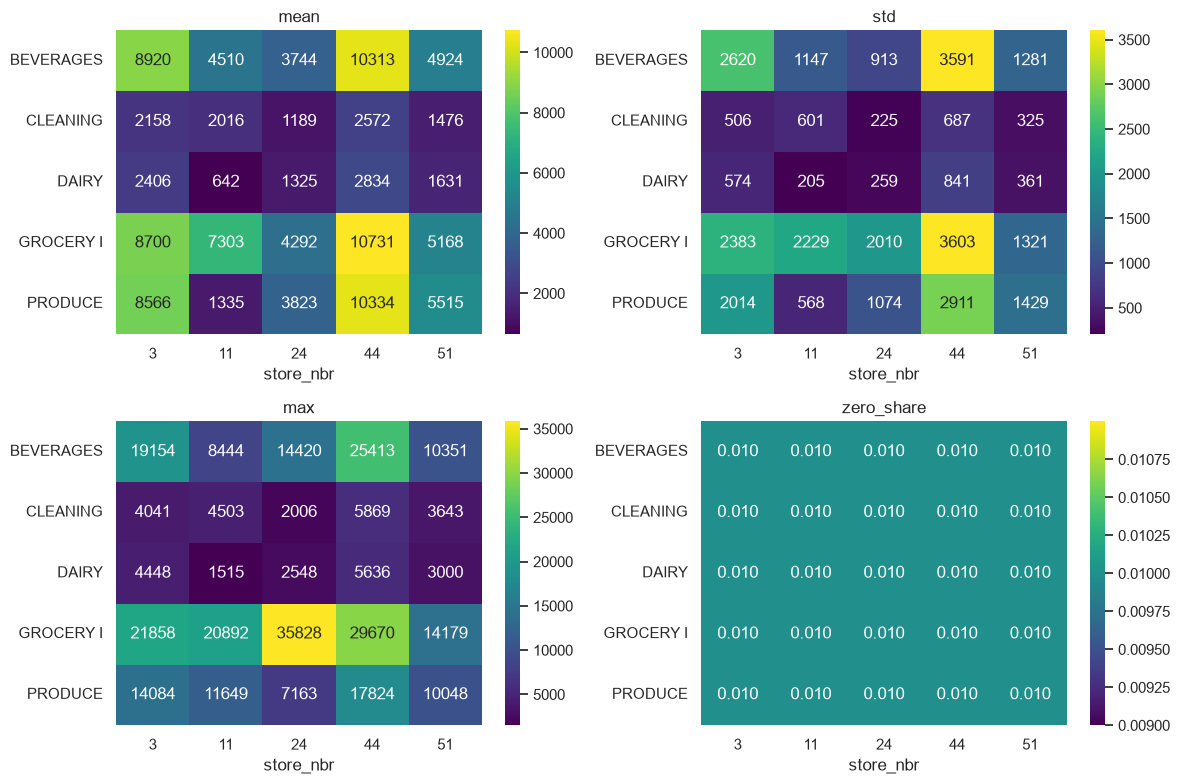

In [47]:
stats = eda.groupby(["family", "store_nbr"], observed=True).sales.agg(
    mean="mean", std="std", max="max", zero_share=lambda s: (s == 0).mean()
).round(2)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col, fmt in zip(
    axes.ravel(), ["mean", "std", "max", "zero_share"], [".0f", ".0f", ".0f", ".3f"]
):
    sns.heatmap(
        stats[col].unstack(), annot=True, fmt=fmt, cmap="viridis", ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("store_nbr")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

## Total sales over time (by family and store)

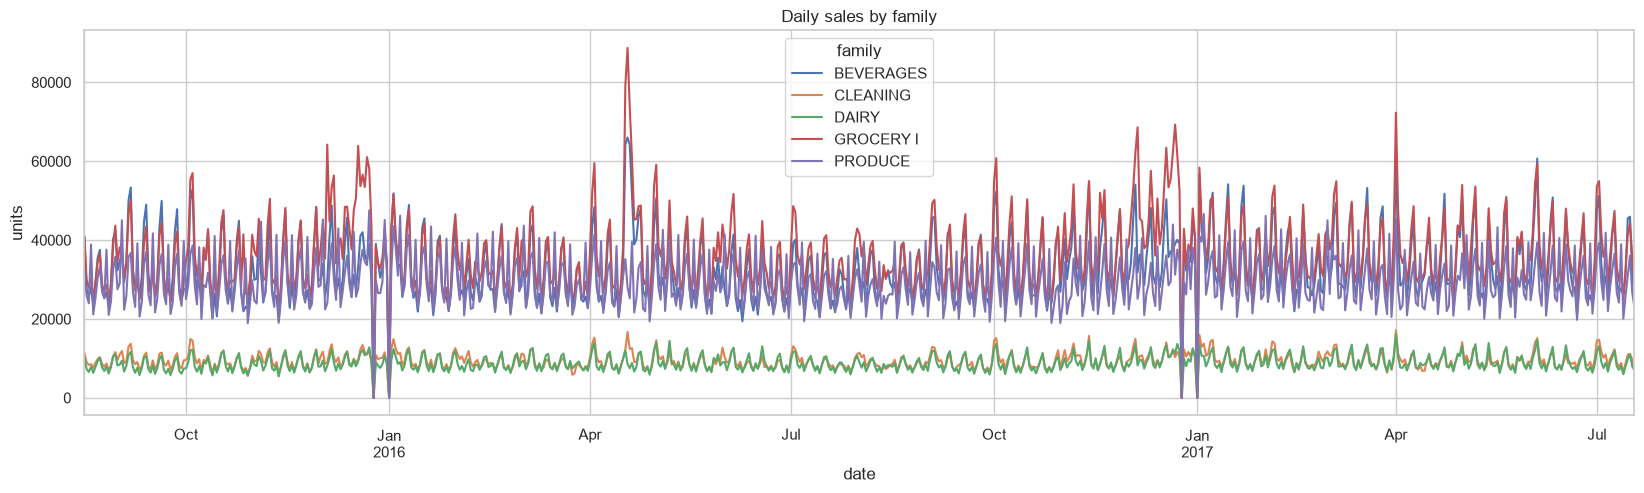

None

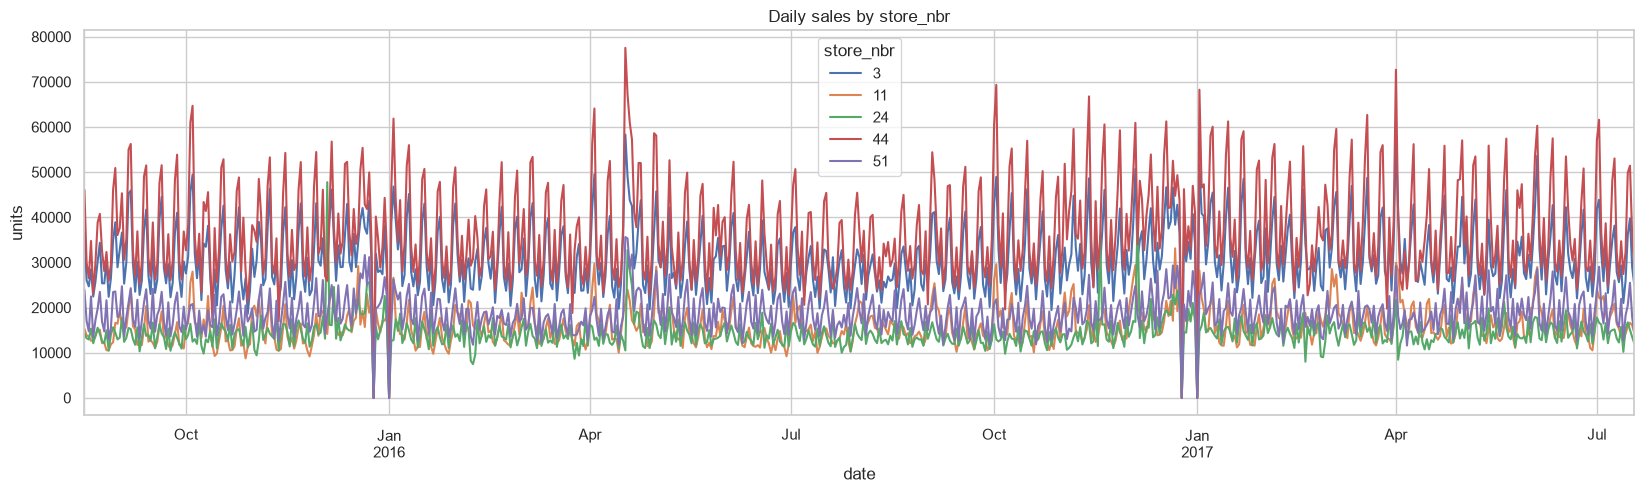

None

In [48]:
def plot_daily(by):
    daily = eda.groupby(["date", by], observed=True).sales.sum().unstack()
    daily.plot(figsize=(20, 5), title=f"Daily sales by {by}")
    plt.ylabel("units")
    plt.show()

display(plot_daily("family"))
display(plot_daily("store_nbr"))

# Check and mark zero days

In [49]:
zero_days = eda.groupby("date").sales.sum()
print(zero_days[zero_days < zero_days.median() * 0.2])

closed_dates = zero_days[zero_days == 0].index
eda.loc[eda.date.isin(closed_dates), "is_closed"] = True
eda.loc[eda.is_closed, "holiday_national"] = True

print(eda.groupby("date").is_closed.first().sum())
print(eda[eda.is_closed].groupby("date").holiday_national.all())

date
2015-12-25    0.0
2016-01-01    0.0
2016-12-25    0.0
2017-01-01    0.0
Name: sales, dtype: float32
4
date
2015-12-25    True
2016-01-01    True
2016-12-25    True
2017-01-01    True
Name: holiday_national, dtype: bool


## Weekday seasonality (by family and store)

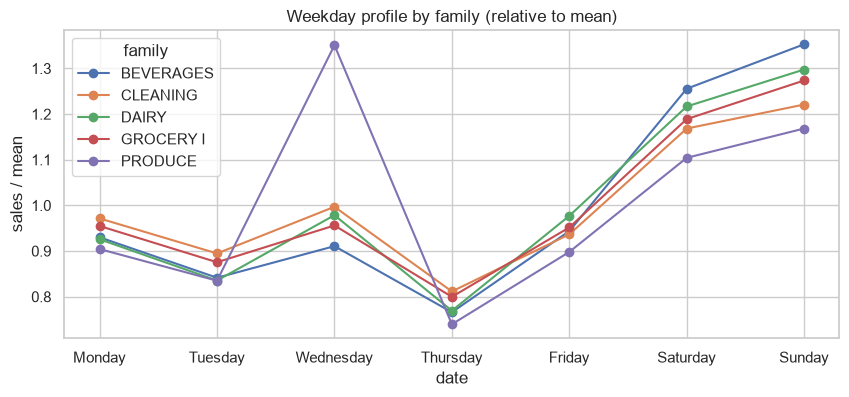

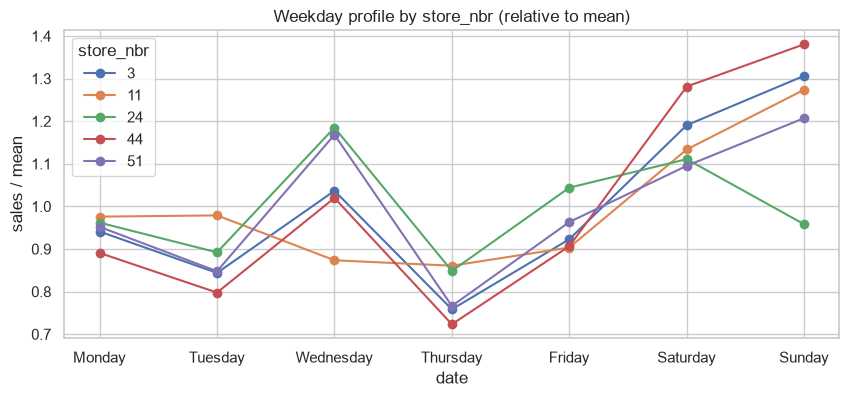

In [50]:
open_days = eda[~eda.is_closed].copy()

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def plot_weekday_profile(by):
    table = (
        open_days.groupby([open_days.date.dt.day_name(), by], observed=True)
        .sales.mean().unstack().loc[WEEKDAYS]
    )
    (table / table.mean()).plot(
        figsize=(10, 4), marker="o",
        title=f"Weekday profile by {by} (relative to mean)",
    )
    plt.ylabel("sales / mean")
    plt.show()

plot_weekday_profile("family")
plot_weekday_profile("store_nbr")

## Month seasonality (by family and store)

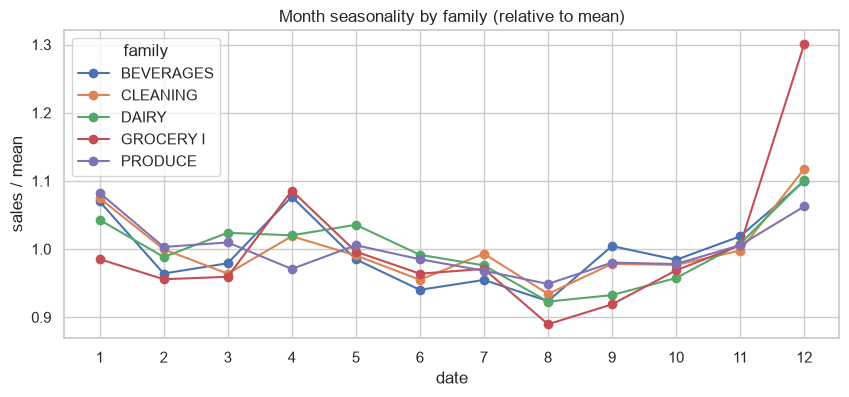

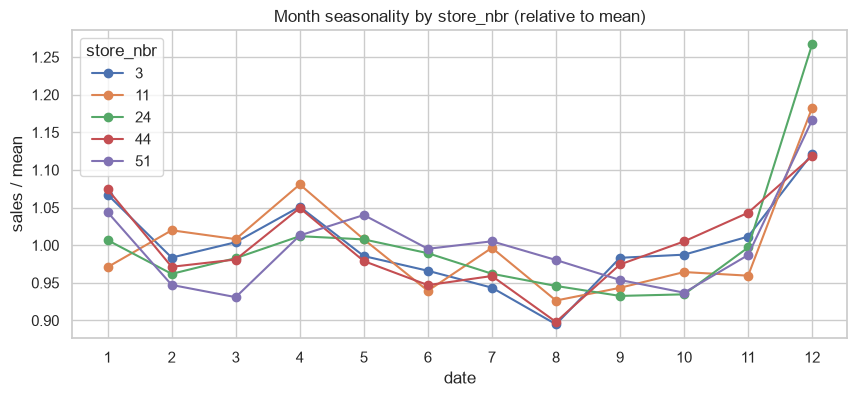

In [51]:
def plot_month_profile(by):
    table = (
        open_days.groupby([open_days.date.dt.month, by], observed=True)
        .sales.mean().unstack()
    )
    (table / table.mean()).plot(
        figsize=(10, 4), marker="o",
        title=f"Month seasonality by {by} (relative to mean)",
    )
    plt.xticks(range(1, 13))
    plt.ylabel("sales / mean")
    plt.show()

plot_month_profile("family")
plot_month_profile("store_nbr")

## Autocorrelation

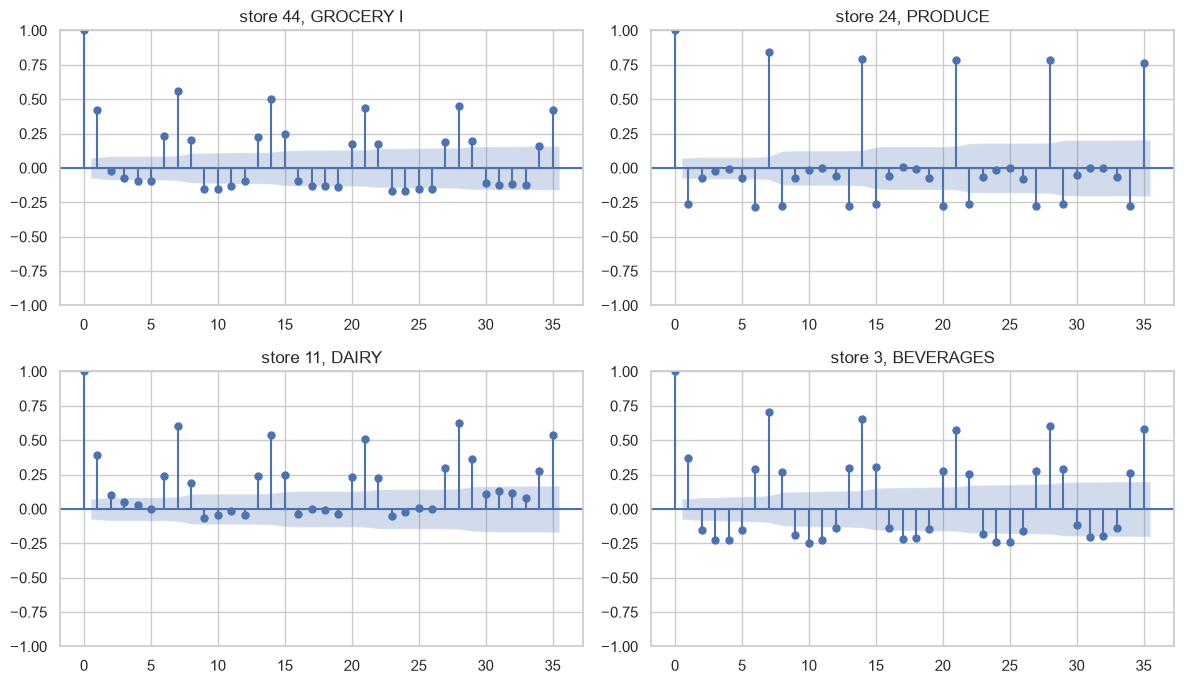

In [52]:
pairs = [(44, "GROCERY I"), (24, "PRODUCE"), (11, "DAIRY"), (3, "BEVERAGES")]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (store, fam) in zip(axes.ravel(), pairs):
    s = eda[(eda.store_nbr == store) & (eda.family == fam)].set_index("date").sales
    plot_acf(s, lags=35, ax=ax)
    ax.set_title(f"store {store}, {fam}")
plt.tight_layout()
plt.show()

## Holidays and events effect (by family and store)

In [53]:
flags = ["holiday_national", "holiday_local", "is_event"]

def flag_effect(by, flags):
    ratios = {}
    for f in flags:
        g = open_days.groupby([by, f], observed=True).sales.mean().unstack()
        ratios[f] = g[True] / g[False]
    return pd.DataFrame(ratios).round(2)

display(flag_effect("family", flags))
display(flag_effect("store_nbr", flags))

,holiday_national,holiday_local,is_event
family,,,
BEVERAGES,1.16,1.51,1.12
CLEANING,1.13,1.26,1.03
DAIRY,1.18,1.43,1.02
GROCERY I,1.25,1.45,1.14
PRODUCE,1.08,1.41,0.99


,holiday_national,holiday_local,is_event
store_nbr,,,
3,1.14,1.22,1.05
11,1.25,0.83,1.05
24,1.06,0.69,1.08
44,1.21,1.22,1.08
51,1.14,0.83,1.12


## Promotion effect (by family and store)

In [54]:
open_days["promo"] = open_days.onpromotion > 0

def promo_effect(by):
    share = open_days.groupby(by, observed=True).promo.mean().rename("promo_share")
    return flag_effect(by, ["promo"]).join(share.round(2))

display(promo_effect("family"))
display(promo_effect("store_nbr"))

,promo,promo_share
family,,
BEVERAGES,1.25,0.99
CLEANING,1.11,0.94
DAIRY,1.30,0.89
GROCERY I,1.19,0.99
PRODUCE,1.09,0.65


,promo,promo_share
store_nbr,,
3,0.90,0.91
11,2.48,0.87
24,1.03,0.89
44,0.86,0.91
51,0.91,0.89


## Promotion coverage over time

In [55]:
promo_by_month = open_days.groupby(open_days.date.dt.to_period("M")).promo.mean().round(2)
promo_by_month

date
2015-08    0.74
2015-09    0.82
2015-10    0.82
2015-11    0.77
2015-12    0.81
2016-01    0.72
2016-02    0.61
2016-03    0.78
2016-04    0.83
2016-05    0.90
2016-06    0.93
2016-07    0.93
2016-08    0.98
2016-09    0.92
2016-10    0.99
2016-11    0.96
2016-12    1.00
2017-01    1.00
2017-02    0.99
2017-03    0.96
2017-04    0.99
2017-05    1.00
2017-06    0.95
2017-07    1.00
Freq: M, Name: promo, dtype: float64

## Promotion count over time

In [56]:
by_month = open_days.groupby(open_days.date.dt.to_period("M")).agg(
    sales=("sales", "mean"), onpromotion=("onpromotion", "mean")
).round(1)
by_month

,sales,onpromotion
date,,
2015-08,4358.299805,9.4
2015-09,4594.600098,12.9
2015-10,4527.500000,9.4
2015-11,4576.500000,15.2
2015-12,5260.100098,16.1
2016-01,4741.500000,12.3
2016-02,4399.799805,22.7
2016-03,4335.399902,19.0
2016-04,5054.600098,25.1


## Oil price vs sales

       sales    oil
sales  1.000  0.061
oil    0.061  1.000


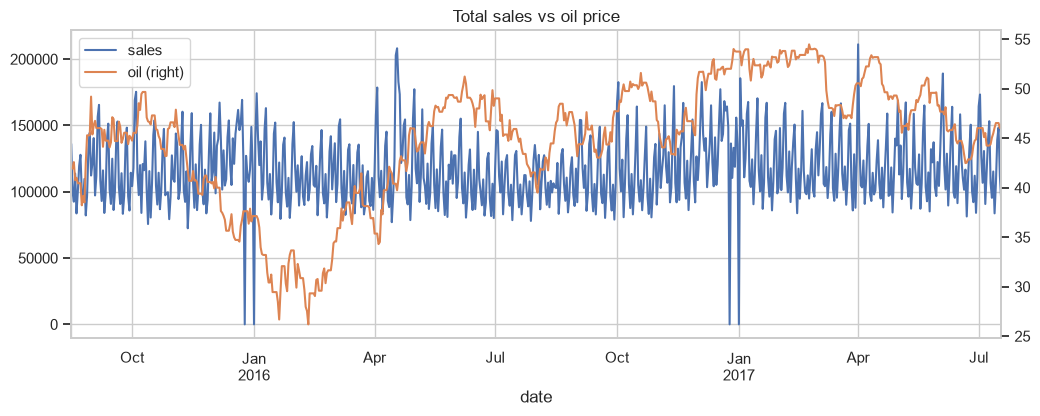

In [57]:
oil_daily = eda.groupby("date").agg(sales=("sales", "sum"), oil=("dcoilwtico", "first"))
print(oil_daily.corr().round(3))

oil_daily.plot(secondary_y="oil", figsize=(12, 4), title="Total sales vs oil price")
plt.show()

# Outliers

### Sales (z-score and IQR)

In [58]:
def find_outliers(df):
    g = df.groupby(["store_nbr", "family"], observed=True).sales
    z = (df.sales - g.transform("mean")) / g.transform("std")
    q1, q3 = g.transform(lambda s: s.quantile(0.25)), g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    out = df.assign(
        z_outlier=z.abs() > 3,
        iqr_outlier=(df.sales < q1 - 1.5 * iqr) | (df.sales > q3 + 1.5 * iqr),
    )
    return out[out.z_outlier | out.iqr_outlier]

outliers = find_outliers(open_days)
print(outliers[["z_outlier", "iqr_outlier"]].sum())
print("both:", (outliers.z_outlier & outliers.iqr_outlier).sum())

z_outlier      135
iqr_outlier    445
dtype: int64
both: 135


### Outlier inspection (calls removed)

The functions in the next cell were used during EDA to look at the largest outliers (top rows, holiday and event flags, promotion on those dates). Their calls and outputs were removed so that the repository does not contain rows of the Kaggle data (redistribution is not allowed). The insights from them are in the conclusions below.

Insights:
- The largest outliers are real events, not data errors: the April 2016 earthquake (Apr 17-19 and 30, stores 44 and 3), early December peaks in store 24 (2015-12-04, 2016-12-05), pre-Christmas days (2016-12-18).
- The earthquake is covered by the `is_event` flag. The other peaks have no holiday or event flag.
- Promotion explains only the December peaks. On most other peak days `onpromotion` is at or below the median of the series.

In [59]:
def top_outliers(outliers, n=15):
    return outliers.sort_values("sales", ascending=False).head(n)


def outlier_flags(top):
    return top[["date", "store_nbr", "family", "sales", "holiday_national", "holiday_local", "is_event"]]


def outlier_promo(top):
    median_promo = (
        open_days.groupby(["store_nbr", "family"], observed=True)
        .onpromotion.median().rename("median_promo")
    )
    return top[["date", "store_nbr", "family", "sales", "onpromotion"]].merge(
        median_promo, on=["store_nbr", "family"]
    )

# Conclusions

- Series: 25 (5 stores x 5 families), 703 days. Two missing days (Dec 25) were filled, and 4 closed days (Dec 25 and Jan 1 in both years) are marked with `is_closed`.
- Scale differs a lot between families and stores, so scaling is needed for neural networks.
- Strong weekly seasonality (ACF peaks at lags 7, 14, 21, 28). Profiles differ by store and family (PRODUCE peaks on Wednesday, store 24 drops on Sunday).
- December is the only clear yearly peak. The data covers only two years, so other months are not reliable.
- National and local holidays raise sales. The local effect differs by store and is negative in some cities. Regional holidays are absent in the subset, so `holiday_regional` is not used.
- Jan 1 2017 was a transferred holiday but the stores were closed anyway, so closed days are set as national holidays.
- `onpromotion` grows about 4x over the period while sales are flat, so the raw count may drift and a relative version is needed. The binary promo flag is not informative.
- Oil price has almost no relation to sales (correlation 0.06).
- Outliers are real events (earthquake, December peaks) and are kept in the data.
- Most outlier spikes are not explained by promotion or holiday flags, so part of the error is irreducible.